# Домашнее задание: подбор гиперпараметров бустинга и интерпретация модели с SHAP

**Ожидаемое время решения:** 1–1.5 часа.

## Задание

1. Постройте модель градиентного бустинга (LightGBM) на предложенном датасете, подобрав гиперпараметры с помощью Optuna. Исследуйте результаты подбора:
   1. Постройте **parallel coordinate plot** — какие гиперпараметры, судя по графику, можно зафиксировать (не тюнить), а какие критически важны?
   2. Постройте **contour plot** для пары наиболее важных гиперпараметров — хорошо ли подобрана сетка (границы) поиска, или оптимум упирается в край диапазона?
2. Исследуйте SHAP-значения обученной модели:
   1. По **beeswarm** и/или **bar plot** определите, какие признаки являются шумовыми (не влияют на предсказание).
   2. По **dependence plot** найдите интересные попарные взаимодействия признаков.

## Датасет

Мы работаем с синтетическим датасетом **кредитного скоринга** (предсказание дефолта заёмщика).

Формат сдачи: заполненный ноутбук `homework.ipynb`, который можно запустить целиком (Run All) без ошибок.

## 0. Импорт библиотек и генерация датасета

Ниже — готовый код для генерации датасета. Его не нужно менять, просто выполните ячейки.

In [ ]:
!pip install lightgbm optuna plotly shap seaborn pandas numpy matplotlib scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 425.6/425.6 kB 11.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 265.9/265.9 kB 7.5 MB/s eta 0:00:00


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
import lightgbm as lgb

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

RANDOM_STATE = 42

df = pd.read_csv('credit_default_dataset.csv')
print(df.shape)
print(f"Доля дефолтов: {df['default'].mean():.3f}")
df.head()

(5000, 10)
Доля дефолтов: 0.329


,credit_score,debt_to_income,num_late_payments,employment_years,loan_amount,age,num_dependents,random_noise_1,random_noise_2,default
0,791.124188,0.392597,0,11.983732,30789.448624,40.644553,1,-0.459744,-0.302889,0
1,682.012577,0.048017,2,2.989243,16185.904729,63.539670,0,-0.101710,-0.477970,0
2,728.299039,0.220371,2,1.969566,47967.595997,39.928274,1,-0.101684,-0.676613,0
3,829.271456,0.573167,4,5.233681,33381.566076,62.364786,2,-1.101363,-0.439043,1
4,799.404639,0.451384,4,4.912667,9389.584941,32.648320,0,-0.950643,0.333650,0


### Разбиение на train/test

In [ ]:
feature_cols = [c for c in df.columns if c != 'default']
X = df[feature_cols]
y = df['default']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y
)
X_train.shape, X_test.shape

((3500, 9), (1500, 9))

## 1. Подбор гиперпараметров LightGBM с помощью Optuna (4 балла)

**Задание:** напишите objective-функцию для Optuna, которая обучает `lgb.train` с подсказанными (`trial.suggest_*`) гиперпараметрами и возвращает AUC на валидационной выборке (`X_test`, `y_test`). Используйте early stopping.

Рекомендуемое пространство поиска (можно скорректировать):
- `num_leaves`: int, [10, 200]
- `learning_rate`: float, [0.01, 0.3], log scale
- `feature_fraction`: float, [0.5, 1.0]
- `bagging_fraction`: float, [0.5, 1.0]
- `bagging_freq`: int, [1, 10]
- `lambda_l1`: float, [1e-8, 10.0], log scale
- `lambda_l2`: float, [1e-8, 10.0], log scale

Запустите не менее 50 trials.

In [ ]:
import optuna

train_data = lgb.Dataset(X_train, label=y_train)
valid_data = lgb.Dataset(X_test, label=y_test, reference=train_data)


def objective(trial):
    params = {
        'objective': 'binary',
        'metric': 'auc',
        'verbosity': -1,
        'boosting_type': 'gbdt',
        'random_state': RANDOM_STATE,
        # TODO: задайте гиперпараметры через trial.suggest_*
        'num_leaves': trial.suggest_int('num_leaves', 10, 200),
        'learning_rate': trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        'feature_fraction': trial.suggest_float("feature_fraction", 0.5, 1.0),
        'bagging_fraction': trial.suggest_float("bagging_fraction", 0.5, 1.0),
        'bagging_freq': trial.suggest_int("bagging_freq", 1, 10),
        'lambda_l1': trial.suggest_float("lambda_l1", 1e-8, 10.0, log=True),
        'lambda_l2': trial.suggest_float("lambda_l2", 1e-8, 10.0, log=True),
    }

    # TODO: обучите модель с early stopping и верните AUC на валидации
    callbacks = [lgb.early_stopping(stopping_rounds=30, verbose=False)]
    model = lgb.train(
      params,
      train_data,
      num_boost_round=1000,
      valid_sets=[valid_data],
      callbacks=callbacks,
  )
    y_pred = model.predict(X_test, num_iteration=model.best_iteration)
    auc = roc_auc_score(y_test, y_pred)

    return auc


# TODO: создайте study и запустите optimize (n_trials >= 50)
study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE),
)
study.optimize(objective, n_trials=69, show_progress_bar=True)

print("Best params:", study.best_params)
print("Best AUC:", study.best_value)

[I 2026-08-17 08:23:52,221] A new study created in memory with name: no-name-71514465-09f2-4cb3-9020-10c10e05fe02


  0%|          | 0/69 [00:00<?, ?it/s]

[I 2026-08-17 08:23:53,075] Trial 0 finished with value: 0.7817951822032789 and parameters: {'num_leaves': 81, 'learning_rate': 0.2536999076681772, 'feature_fraction': 0.8659969709057025, 'bagging_fraction': 0.7993292420985183, 'bagging_freq': 2, 'lambda_l1': 2.5348407664333426e-07, 'lambda_l2': 3.3323645788192616e-08}. Best is trial 0 with value: 0.7817951822032789.
[I 2026-08-17 08:23:53,672] Trial 1 finished with value: 0.7986165804883061 and parameters: {'num_leaves': 175, 'learning_rate': 0.07725378389307355, 'feature_fraction': 0.8540362888980227, 'bagging_fraction': 0.5102922471479012, 'bagging_freq': 10, 'lambda_l1': 0.31044435499483225, 'lambda_l2': 8.148018307012941e-07}. Best is trial 1 with value: 0.7986165804883061.
[I 2026-08-17 08:23:54,364] Trial 2 finished with value: 0.8131859941867373 and parameters: {'num_leaves': 44, 'learning_rate': 0.018659959624904916, 'feature_fraction': 0.6521211214797689, 'bagging_fraction': 0.762378215816119, 'bagging_freq': 5, 'lambda_l1': 

### 1.1 Обучение финальной модели с лучшими параметрами

**Задание:** обучите LightGBM с параметрами `study.best_params` на полном train, сохраните модель в переменную `model_lgb` — она понадобится для SHAP-анализа далее.

In [ ]:
best_params = study.best_params.copy()
best_params.update({'objective': 'binary', 'metric': 'auc', 'verbosity': -1, 'random_state': RANDOM_STATE})

# TODO: обучите финальную модель model_lgb с best_params
callbacks = [lgb.early_stopping(stopping_rounds=30, verbose=False)]

model_lgb = lgb.train(
    best_params,
    train_data,
    num_boost_round=1000,
    valid_sets=[valid_data],
    callbacks=callbacks,
)

# TODO: посчитайте и выведите AUC на train и test
y_train_pred = model_lgb.predict(X_train, num_iteration=model_lgb.best_iteration)
y_test_pred = model_lgb.predict(X_test, num_iteration=model_lgb.best_iteration)

train_auc = roc_auc_score(y_train, y_train_pred)
test_auc = roc_auc_score(y_test, y_test_pred)

print(f'Train AUC {train_auc}')
print(f'Test AUC {test_auc}')

Train AUC 0.8646458126301343
Test AUC 0.8210780117272399


### 1.2 Parallel coordinate plot

**Задание:** постройте parallel coordinate plot для `study`. Изучите график и ответьте письменно (в markdown-ячейке ниже): какие гиперпараметры, судя по графику, слабо влияют на итоговый AUC и их можно было бы зафиксировать на разумном значении по умолчанию, чтобы сократить пространство поиска?

In [ ]:
from optuna.visualization import plot_parallel_coordinate

# TODO: постройте parallel coordinate plot
plot_parallel_coordinate(study)


**Ваш ответ:**

Буду отталкиваться от значений по умолчанию.

num_leaves: основная масса близких к максимальному auc value находится от 80 до 120 , значение по умолчанию 31, значит он неплохо влияет ведь, рядом со значением по умолчанию проходит очень мало линий.

lr: здесь немного сложнее ответить, ведь высоких скор равномерно рассредодочен между 0.1 и 0.01, и чего можно сказать что влияние не особо сущесвенное, но все же рядом со значением по умолчанию (0.1) мало решений с большым auc поэтому все таки стоит выбрать lr.

l2: Хоть и большая часть расположены рядом с 0, но регуляризация влияет на обобщающую способность модели, поэтому не думаю. что стоит убирать ее

l1: основная часть проходит через >1 поэтому стоит оставить видимо есть какие то слабые признаки.

feature_fraction: основная часть больших скоров проходит рядом с 1 следовательно здесь можно не подбирать и оставить 1. Возможно это свзязано с небольным количеством семплов для обучения.

bagging_freq: Стоит подбирать так как влияет на обучение, 1 и 2 основные кандиаты.

bagging_fraction: здесь тоже около 0.6 основная масса хороших резульатов, значит неплохо влияет данный гиперпараметр, следовательно его тоже следует подбирать.

**Итог:**  слабо влияет l2 параметр так как хаотично разбросанны в своем диапозоне, но подбирать его все же следует, в отличии от feature_fraction, его значение по умолчанию думаю устроит нас так как основная масса решений сосредаточена возле 1.


### 1.3 Contour plot

**Задание:** выберите два гиперпараметра, которые (судя по `plot_param_importances`) сильнее всего влияют на метрику, и постройте для них contour plot. Ответьте: находится ли найденный оптимум внутри заданных границ поиска, или он «упирается» в край диапазона? Если упирается — как нужно было бы изменить границы поиска?

In [ ]:
from optuna.visualization import plot_param_importances, plot_contour

# TODO: постройте plot_param_importances(study)
fig_importance = plot_param_importances(study)
fig_importance.show()

# TODO: выберите два наиболее важных гиперпараметра и постройте для них plot_contour(study, params=[...])
importances = optuna.importance.get_param_importances(study)
top_2_params = list(importances.keys())[:2]

fig_contour = plot_contour(study, params=top_2_params)
fig_contour.show()


**Ваш ответ:** Упирается в правую границу основные значения расположены там, нужно расширить диапозон для lambda_l1

## 2. Интерпретация модели с помощью SHAP (4 балла)

**Задание:** пересчитайте SHAP-значения для обученной модели `model_lgb` на тестовой выборке с помощью `shap.TreeExplainer`.

In [ ]:
import shap

# TODO: создайте explainer
explainer = shap.TreeExplainer(model_lgb)

# TODO: посчитайте shap_values для X_test
shap_values = explainer(X_test)

feature_names = feature_cols

### 2.1 Beeswarm / bar plot — поиск шумовых признаков

**Задание:** постройте beeswarm plot (`shap.summary_plot`) и bar plot (агрегированная важность). Определите, какие признаки являются шумовыми (SHAP value близок к нулю для всех наблюдений). Совпадает ли ваш список с тем, что вы ожидали, глядя на названия признаков?

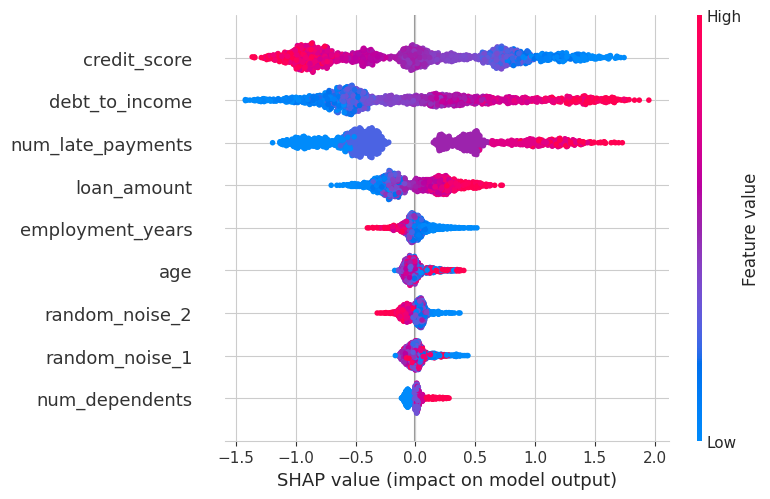

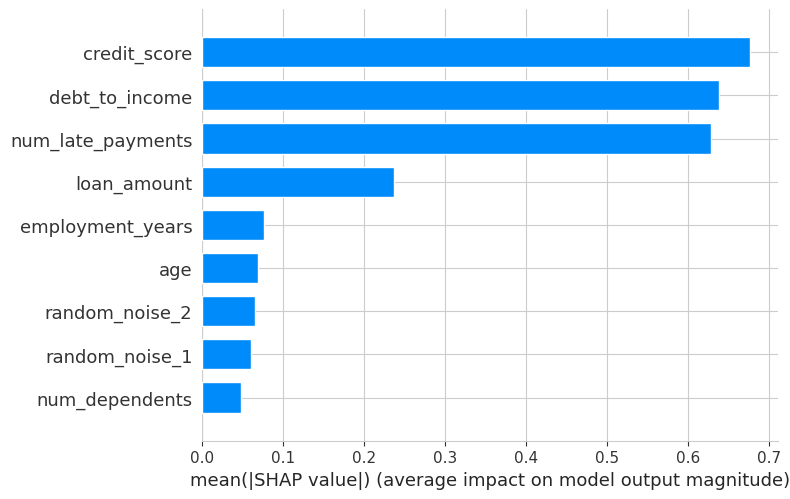

In [ ]:
# TODO: постройте beeswarm plot
shap.summary_plot(shap_values, X_test, feature_names=feature_names)

# TODO: постройте bar plot (агрегированная важность)
shap.summary_plot(shap_values, X_test, feature_names=feature_names, plot_type='bar')


**Ваш ответ:** Шумовыми являются с низким средним shap value, например как у шумовых признаков. Порядок влияния возраста и стажа немного удивил.

### 2.2 Dependence plot — поиск попарных взаимодействий

**Задание:** постройте dependence plot для 2-3 наиболее важных признаков (по умолчанию SHAP сам подберёт цвет по признаку с наибольшим взаимодействием). Найдите признак, у которого зависимость SHAP value от значения самого признака выглядит по-разному в зависимости от цвета (значения второго признака) — это и есть взаимодействие. Дополнительно постройте dependence plot с явно заданным `interaction_index`, чтобы проверить гипотезу о конкретной паре признаков.

['credit_score', 'debt_to_income', 'num_late_payments', 'employment_years', 'loan_amount', 'age', 'num_dependents', 'random_noise_1', 'random_noise_2']


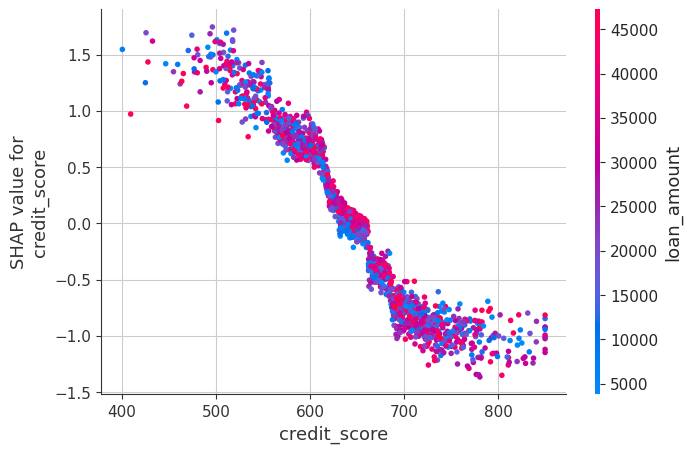

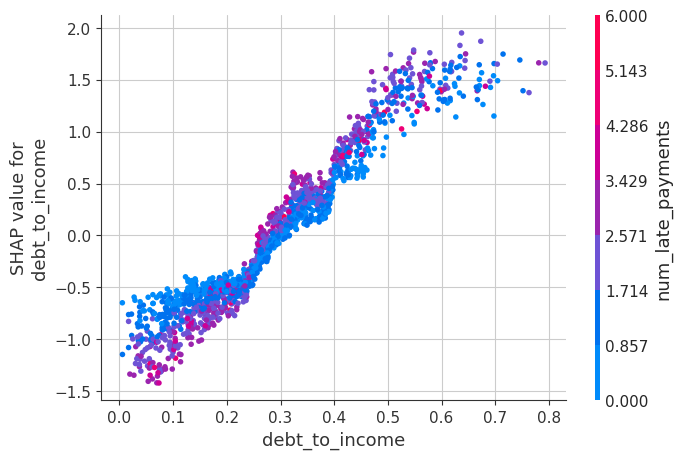

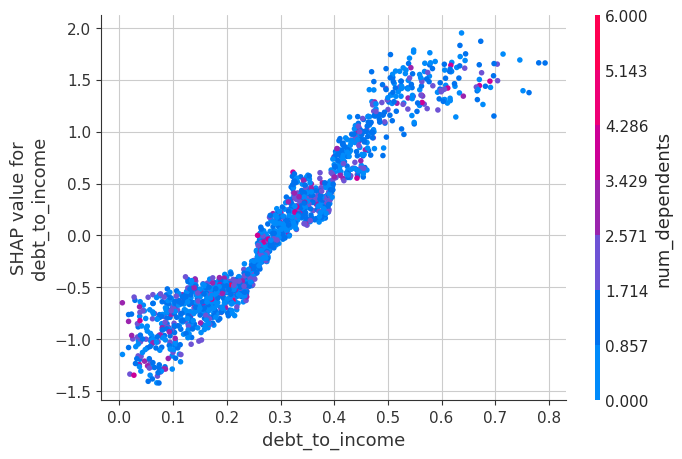

In [ ]:
# TODO: постройте dependence plot для наиболее важного признака (по умолчанию)
print(feature_names)
shap.dependence_plot('credit_score', shap_values.values, X_test, feature_names=feature_names)

shap.dependence_plot('debt_to_income', shap_values.values, X_test, feature_names=feature_names)

# TODO: постройте dependence plot с явно заданным interaction_index для проверки конкретной гипотезы
shap.dependence_plot('debt_to_income', shap_values.values, X_test, feature_names=feature_names, interaction_index='num_dependents')


**Ваш ответ:** Ну мне удалось только найти debt_to_income и num_dependents, думаю график с синими и остальными точками сильно различается как минимум порядком точек. Все остальные проверенные мной были примерно похожи в отдельных цветах.

## 3. Итоговые выводы (3 балла)

Кратко (в виде bullet points) резюмируйте:
- Какие гиперпараметры оказались важны, а какие можно было не тюнить?
  - Ответ: Судя по plot_param_importances самыми важными оказались lr и l1 гиперпараметры, по parallel coordinate plot я выделил и много других, но данный график не отражает видимо насколько они важны. l1 оказался важным из за большого количества шумовых признаков. l2 и num_leaves отошли на второй план, хотя мне кажется что тюнить их следует. Не тюнить можно было feature_fraction, plot_param_importances это подтвердил.
- Была ли сетка поиска гиперпараметров задана удачно?
  - Ответ: Скорее нет, так как наилучшие значения l1 были сконцентрированны у правой границы.
- Какие признаки оказались шумовыми?
  - Ответ: По сути в шумовые можно определить все кроме 4:
    'credit_score', 'debt_to_income', 'num_late_payments',  'loan_amount'
- Какое взаимодействие признаков вы обнаружили и согласуется ли оно с вашей интуицией о кредитном риске?
  - Ответ: Сложно сказать так как я не очень понимаю что значит 'num_dependents' признак и он показано что не несет большого значения, но все остальные мне показались, что не сильно меняются в зависимости от цвета. Предположу, что этот признак говорит о детях и других людях на обеспечении, и если так то видимо тут сильную связь тяжело уловить из-за разряженности признака. Единственное предположение, которое тут можно сказать, что бОльшие значение сосредаточены в нижней части, видимо не хотят брать большой кредит в таком положении.